# Computer Vision Assignment 3

Interactive implementation of image restoration, segmentation, feature extraction, object recognition, and video motion estimation.

**Photo input:** the supplied `Sneh.heif`, converted to `data/original_photo.png` (4032 × 2268). This notebook uses that photo and does not replace it.

**Video input:** `data/original_video.mp4` contains the supplied outdoor recording (720 × 1280, 54 frames at approximately 29.9 fps). The pipeline analyzes this clip and will not synthesize a replacement.



## 1. Setup and dependencies

Run the package installation cell once. The next code cell automatically uses the local project folder or clones the inputs from GitHub in Colab; no separate requirements file is needed. The GitHub repository must be publicly accessible for anonymous Colab cloning.

In [1]:
%pip install -q "opencv-python<5" scikit-image matplotlib pandas ultralytics

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import subprocess
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage import exposure
from skimage.feature import hog
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from ultralytics import YOLO

# Use the local project when present; otherwise clone the input assets for Colab.
REPO_URL = "https://github.com/SnehPatel7704/Computer-Vision.git"
REPO_DIR = Path("/content/Computer-Vision")
candidates = (Path.cwd(), *Path.cwd().parents, REPO_DIR)
ROOT = next((p for p in candidates if (p / "data" / "original_photo.png").is_file() and (p / "data" / "original_video.mp4").is_file()), None)
if ROOT is None and not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
    ROOT = REPO_DIR
if ROOT is None:
    raise FileNotFoundError(f"Could not find the photo/video inputs in the cloned GitHub project: {REPO_DIR}")

DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# Keep OpenCV image output failures explicit instead of silently continuing.
def save_image(path, image):
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not save image: {path}")

print(f"Project directory: {ROOT}")

Project directory: /Users/snehpatel/MIT/Git/Computer-Vision


## 2. Input photo

Review the supplied image before processing. The source file is retained in the project root as `Sneh.heif`; the PNG copy is used by OpenCV.

Input: data/original_photo.png
Image dimensions: 4032 × 2268 pixels


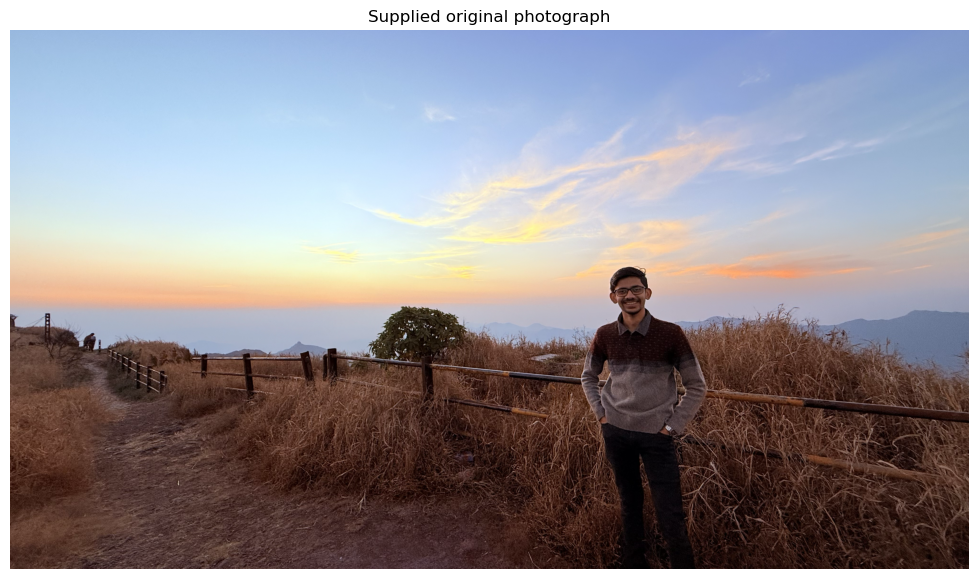

In [3]:
# OpenCV loads color images as BGR; convert to RGB only for Matplotlib display.
photo_path = DATA_DIR / "original_photo.png"
photo_bgr = cv2.imread(str(photo_path), cv2.IMREAD_COLOR)
if photo_bgr is None:
    raise FileNotFoundError(f"Could not read input image: {photo_path}")
photo_rgb = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2RGB)

print(f"Input: {photo_path.relative_to(ROOT)}")
print(f"Image dimensions: {photo_bgr.shape[1]} × {photo_bgr.shape[0]} pixels")
plt.figure(figsize=(14, 7))
plt.imshow(photo_rgb)
plt.title("Supplied original photograph")
plt.axis("off")
plt.show()

## 3. Image restoration

Add Gaussian and salt-and-pepper noise. Apply both Gaussian and median filters to each noisy image, then compare all restored grayscale results with the original using PSNR and SSIM. A fixed random seed makes the comparison reproducible.

Restoration measurements:
gaussian_noise_gaussian_filter: PSNR=32.7408, SSIM=0.8581
gaussian_noise_median_filter: PSNR=31.9501, SSIM=0.8182
salt_pepper_gaussian_filter: PSNR=27.6546, SSIM=0.6334
salt_pepper_median_filter: PSNR=33.8344, SSIM=0.9094


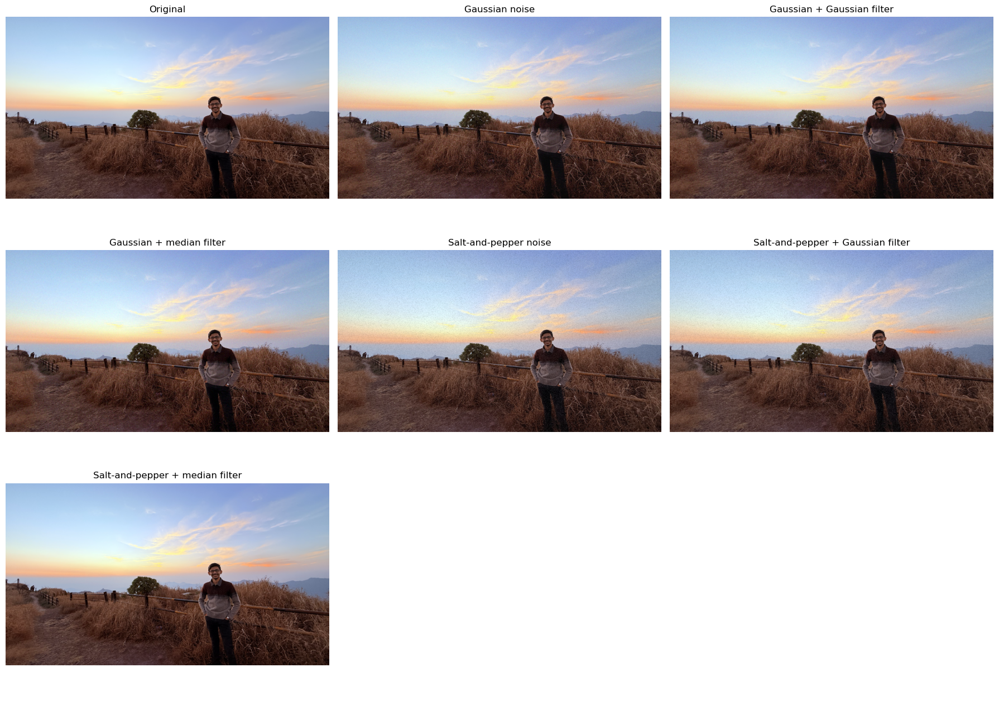

,PSNR (dB),SSIM
Noise + restoration method,,
gaussian_noise_gaussian_filter,32.7408,0.8581
gaussian_noise_median_filter,31.9501,0.8182
salt_pepper_gaussian_filter,27.6546,0.6334
salt_pepper_median_filter,33.8344,0.9094


In [4]:
# A fixed seed makes the noise and the PSNR/SSIM comparison reproducible.
rng = np.random.default_rng(42)
gaussian_noise = rng.normal(0, 20, photo_bgr.shape).astype(np.float32)
noisy_gaussian = np.clip(cv2.add(photo_bgr.astype(np.float32), gaussian_noise), 0, 255).astype(np.uint8)

salt_pepper = photo_bgr.copy()
# Assign the same random impulse decision to all three channels for each pixel.
flat = salt_pepper.reshape(-1, 3)
random_values = rng.random(flat.shape[0])
flat[random_values < 0.03] = 0
flat[random_values > 0.97] = 255

# Compare both filters against both noise types to show their strengths and limits.
restored_images = {
    "gaussian_noise_gaussian_filter": cv2.GaussianBlur(noisy_gaussian, (5, 5), 1.5),
    "gaussian_noise_median_filter": cv2.medianBlur(noisy_gaussian, 5),
    "salt_pepper_gaussian_filter": cv2.GaussianBlur(salt_pepper, (5, 5), 1.5),
    "salt_pepper_median_filter": cv2.medianBlur(salt_pepper, 5),
}
restoration_results = {}
original_gray = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2GRAY)
# PSNR and SSIM are measured on grayscale images with the original as reference.
for method, restored in restored_images.items():
    restored_gray = cv2.cvtColor(restored, cv2.COLOR_BGR2GRAY)
    restoration_results[method] = {
        "PSNR (dB)": peak_signal_noise_ratio(original_gray, restored_gray, data_range=255),
        "SSIM": structural_similarity(original_gray, restored_gray, data_range=255),
    }

save_image(RESULTS_DIR / "noise_gaussian.png", noisy_gaussian)
save_image(RESULTS_DIR / "noise_salt_pepper.png", salt_pepper)
for method, restored in restored_images.items():
    save_image(RESULTS_DIR / f"restored_{method}.png", restored)
print("Restoration measurements:")
for method, metrics in restoration_results.items():
    print(f"{method}: PSNR={metrics['PSNR (dB)']:.4f}, SSIM={metrics['SSIM']:.4f}")

restoration_files = [
    ("Original", DATA_DIR / "original_photo.png"),
    ("Gaussian noise", RESULTS_DIR / "noise_gaussian.png"),
    ("Gaussian + Gaussian filter", RESULTS_DIR / "restored_gaussian_noise_gaussian_filter.png"),
    ("Gaussian + median filter", RESULTS_DIR / "restored_gaussian_noise_median_filter.png"),
    ("Salt-and-pepper noise", RESULTS_DIR / "noise_salt_pepper.png"),
    ("Salt-and-pepper + Gaussian filter", RESULTS_DIR / "restored_salt_pepper_gaussian_filter.png"),
    ("Salt-and-pepper + median filter", RESULTS_DIR / "restored_salt_pepper_median_filter.png"),
]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, (title, path) in zip(axes.flat, restoration_files):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
for ax in axes.flat[len(restoration_files):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

restoration_metrics = pd.DataFrame.from_dict(restoration_results, orient="index")
restoration_metrics.index.name = "Noise + restoration method"
restoration_metrics = restoration_metrics.round(4)
display(restoration_metrics)

## 4. Thresholding, morphology, edges, and watershed

Thresholding and morphological operations are applied to the supplied photo. Watershed uses a separate image with touching circular regions so that the segmentation boundaries are easy to inspect.

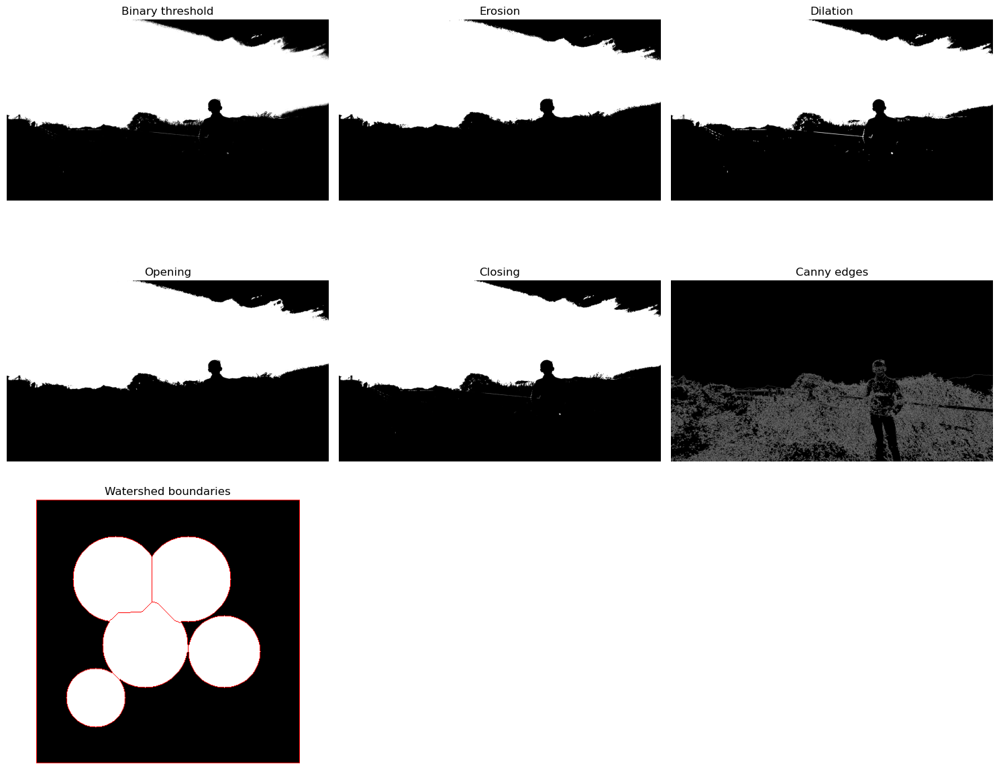

In [5]:
# Threshold grayscale intensity, then compare how the 5x5 kernel changes regions.
gray_photo = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray_photo, 170, 255, cv2.THRESH_BINARY)
kernel = np.ones((5, 5), np.uint8)
morphology_outputs = {
    "binary_threshold.png": binary,
    "morph_erosion.png": cv2.erode(binary, kernel, iterations=1),
    "morph_dilation.png": cv2.dilate(binary, kernel, iterations=1),
    "morph_opening.png": cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel),
    "morph_closing.png": cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel),
    "edge_canny.png": cv2.Canny(gray_photo, 50, 150),
}
for filename, image in morphology_outputs.items():
    save_image(RESULTS_DIR / filename, image)

# Create touching foreground shapes specifically to demonstrate watershed splitting.
objects = np.zeros((400, 400), dtype=np.uint8)
for center, radius in [((120, 120), 65), ((230, 120), 65), ((165, 220), 65), ((285, 230), 55), ((90, 300), 45)]:
    cv2.circle(objects, center, radius, 255, -1)
watershed_kernel = np.ones((3, 3), np.uint8)
# Distance-transform peaks form foreground markers; dilation estimates sure background.
sure_background = cv2.dilate(objects, watershed_kernel, iterations=3)
distance = cv2.distanceTransform(objects, cv2.DIST_L2, 5)
_, sure_foreground = cv2.threshold(distance, 0.55 * distance.max(), 255, cv2.THRESH_BINARY)
sure_foreground = sure_foreground.astype(np.uint8)
unknown = cv2.subtract(sure_background, sure_foreground)
_, markers = cv2.connectedComponents(sure_foreground)
markers += 1
markers[unknown == 255] = 0
watershed_image = cv2.cvtColor(objects, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(watershed_image, markers)
watershed_image[markers == -1] = (0, 0, 255)
save_image(RESULTS_DIR / "watershed_segmentation.png", watershed_image)
segmentation_files = [
    ("Binary threshold", "binary_threshold.png"),
    ("Erosion", "morph_erosion.png"),
    ("Dilation", "morph_dilation.png"),
    ("Opening", "morph_opening.png"),
    ("Closing", "morph_closing.png"),
    ("Canny edges", "edge_canny.png"),
    ("Watershed boundaries", "watershed_segmentation.png"),
]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, (title, filename) in zip(axes.flat, segmentation_files):
    image = cv2.imread(str(RESULTS_DIR / filename), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
for ax in axes.flat[len(segmentation_files):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. HOG and SIFT feature matching

The matching pair is derived from the supplied photograph: one scaled view and one resized view of the same scene. The pipeline also repeats matching after rotation and resizing. This is a transformation experiment, not a second independently captured photograph.

{'HOG descriptor length': 109224, 'SIFT keypoints in photo A': 2482, 'SIFT keypoints in photo B': 2039, 'Good matches': 1278, 'Good matches after rotation': 1259, 'Good matches after resizing': 1140}


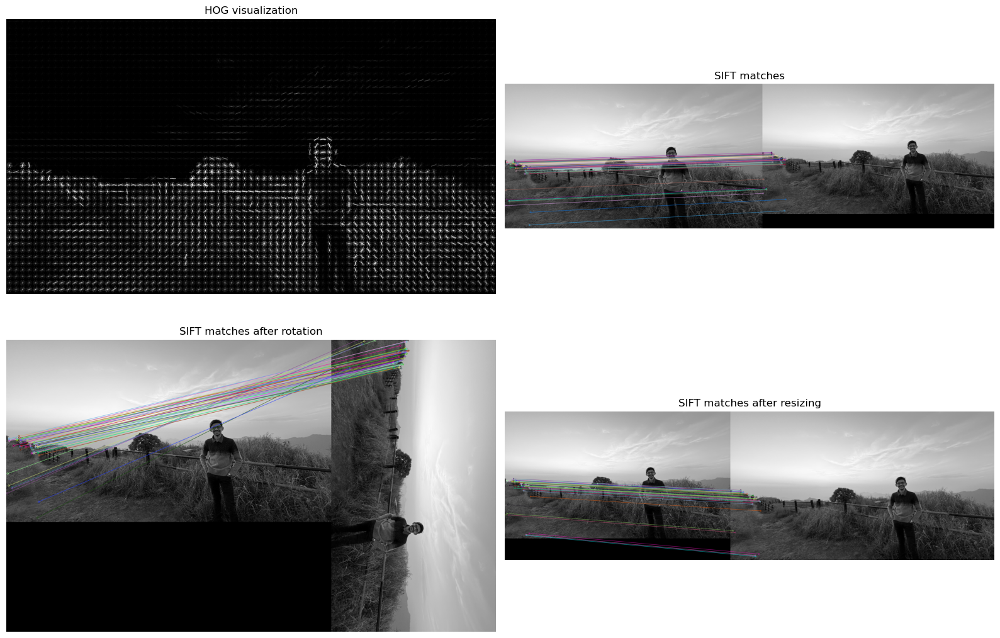

In [6]:
# The pair is derived from this one photo; the second view is resized, not independently captured.
scene_a = cv2.imread(str(photo_path), cv2.IMREAD_COLOR)
scale = min(1.0, 1200 / max(scene_a.shape[:2]))
if scale < 1.0:
    scene_a = cv2.resize(scene_a, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
scene_b = cv2.resize(scene_a, None, fx=0.9, fy=0.9, interpolation=cv2.INTER_AREA)
save_image(DATA_DIR / "scene_a.png", scene_a)
save_image(DATA_DIR / "scene_b.png", scene_b)
gray_a = cv2.cvtColor(scene_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(scene_b, cv2.COLOR_BGR2GRAY)

# HOG summarizes local gradient directions in 16x16 pixel cells and normalized blocks.
hog_descriptor, hog_image = hog(gray_a, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
hog_image = exposure.rescale_intensity(hog_image, in_range=(0, 10))
save_image(RESULTS_DIR / "hog_visualization.png", cv2.cvtColor(np.uint8(hog_image * 255), cv2.COLOR_GRAY2BGR))

sift = cv2.SIFT_create()
keypoints_a, descriptors_a = sift.detectAndCompute(gray_a, None)
keypoints_b, descriptors_b = sift.detectAndCompute(gray_b, None)
matcher = cv2.BFMatcher(cv2.NORM_L2)

# Lowe's ratio test filters ambiguous nearest-neighbor descriptor matches.
def ratio_matches(descriptors_left, descriptors_right):
    pairs = matcher.knnMatch(descriptors_left, descriptors_right, k=2)
    return [first for first, second in pairs if first.distance < 0.75 * second.distance]

good_matches = ratio_matches(descriptors_a, descriptors_b)
save_image(RESULTS_DIR / "sift_matches.png", cv2.drawMatches(gray_a, keypoints_a, gray_b, keypoints_b, good_matches[:50], None, flags=2))
# Repeat the match test on rotated and resized versions to examine SIFT robustness.
rotated = cv2.rotate(gray_b, cv2.ROTATE_90_CLOCKWISE)
resized = cv2.resize(gray_b, None, fx=1.3, fy=1.3, interpolation=cv2.INTER_LINEAR)
keypoints_rotated, descriptors_rotated = sift.detectAndCompute(rotated, None)
keypoints_resized, descriptors_resized = sift.detectAndCompute(resized, None)
rotated_matches = ratio_matches(descriptors_a, descriptors_rotated)
resized_matches = ratio_matches(descriptors_a, descriptors_resized)
save_image(RESULTS_DIR / "sift_matches_rotated.png", cv2.drawMatches(gray_a, keypoints_a, rotated, keypoints_rotated, rotated_matches[:50], None, flags=2))
save_image(RESULTS_DIR / "sift_matches_resized.png", cv2.drawMatches(gray_a, keypoints_a, resized, keypoints_resized, resized_matches[:50], None, flags=2))
feature_results = {
    "HOG descriptor length": len(hog_descriptor),
    "SIFT keypoints in photo A": len(keypoints_a),
    "SIFT keypoints in photo B": len(keypoints_b),
    "Good matches": len(good_matches),
    "Good matches after rotation": len(rotated_matches),
    "Good matches after resizing": len(resized_matches),
}
print(feature_results)

feature_files = [
    ("HOG visualization", "hog_visualization.png"),
    ("SIFT matches", "sift_matches.png"),
    ("SIFT matches after rotation", "sift_matches_rotated.png"),
    ("SIFT matches after resizing", "sift_matches_resized.png"),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (title, filename) in zip(axes.flat, feature_files):
    image = cv2.imread(str(RESULTS_DIR / filename), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Object detection: Haar cascade and YOLO

The Haar cascade detects faces while YOLO provides object classes and confidence values where detections are found. The Haar XML is downloaded on first use if absent; YOLO downloads its pretrained model on first use.

{'Haar faces': 1, 'YOLO objects': 2}


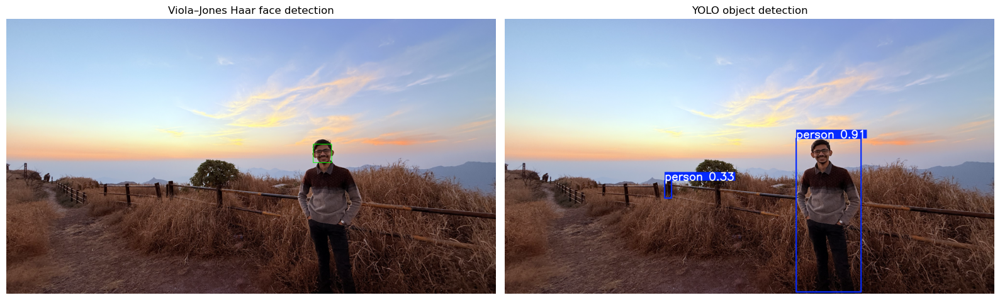

In [7]:
# Run Viola-Jones face detection on grayscale, and draw its boxes on a copy.
image_for_detection = photo_bgr.copy()
gray_for_detection = cv2.cvtColor(image_for_detection, cv2.COLOR_BGR2GRAY)
cascade_path = DATA_DIR / "haarcascades" / "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(str(cascade_path))
if face_cascade.empty():
    raise FileNotFoundError(f"Could not load Haar cascade: {cascade_path}")
# scaleFactor controls pyramid step size; minNeighbors suppresses weak overlapping boxes.
faces = face_cascade.detectMultiScale(gray_for_detection, scaleFactor=1.1, minNeighbors=5)
haar_image = image_for_detection.copy()
for x, y, width, height in faces:
    cv2.rectangle(haar_image, (x, y), (x + width, y + height), (0, 255, 0), 3)
save_image(RESULTS_DIR / "haar_face_detection.png", haar_image)

# YOLO's 0.25 confidence threshold keeps lower-confidence candidate boxes for comparison.
yolo_model = YOLO("yolov8n.pt")
yolo_result = yolo_model(photo_bgr, conf=0.25, verbose=False)[0]
save_image(RESULTS_DIR / "yolo_detection.png", yolo_result.plot(conf=True))
detection_results = {"Haar faces": len(faces), "YOLO objects": len(yolo_result.boxes)}
print(detection_results)
detection_files = [
    ("Viola–Jones Haar face detection", "haar_face_detection.png"),
    ("YOLO object detection", "yolo_detection.png"),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (title, filename) in zip(axes, detection_files):
    image = cv2.imread(str(RESULTS_DIR / filename), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Video motion estimation

This section compares frame differencing, MOG2 background subtraction, and Lucas–Kanade optical flow on consecutive frames of the supplied outdoor video. The clip contains 54 frames (approximately 1.8 seconds); use a longer self-recorded clip if your instructor expects more motion coverage.

Motion-analysis video: data/original_video.mp4


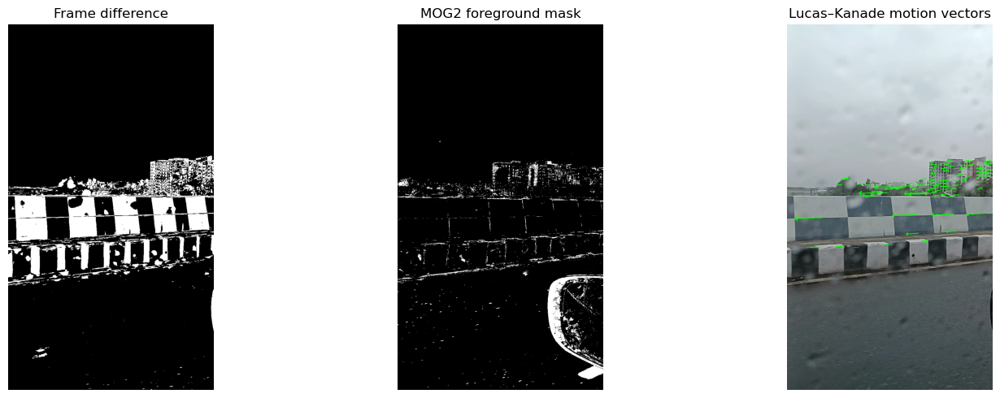

In [8]:
video_path = DATA_DIR / "original_video.mp4"
if not video_path.is_file():
    raise FileNotFoundError(f"Place your self-recorded video at {video_path}")
video_capture = cv2.VideoCapture(str(video_path))
if not video_capture.isOpened() or video_capture.get(cv2.CAP_PROP_FRAME_COUNT) < 2:
    raise ValueError(f"Could not read at least two video frames: {video_path}")
video_capture.release()
print(f"Motion-analysis video: {video_path.relative_to(ROOT)}")

# MOG2 learns a changing background; skip early frames when initialization dominates.
capture = cv2.VideoCapture(str(video_path))
success, previous_frame = capture.read()
if not success:
    raise RuntimeError("Could not read the first video frame")
previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)
background_model = cv2.createBackgroundSubtractorMOG2(history=40, varThreshold=25, detectShadows=True)
best_foreground_mask = None
best_foreground_area = 0
optical_flow_image = None
frame_index = 1
while True:
    success, current_frame = capture.read()
    if not success:
        break
    current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)
    foreground = background_model.apply(current_frame)
    _, foreground_binary = cv2.threshold(foreground, 200, 255, cv2.THRESH_BINARY)
    foreground_area = cv2.countNonZero(foreground_binary)
    # Keep the largest post-warm-up mask for a clear foreground visualization.
    if frame_index >= 5 and foreground_area > best_foreground_area:
        best_foreground_area = foreground_area
        best_foreground_mask = foreground_binary.copy()
    # Lucas-Kanade tracks detected corners between adjacent grayscale frames.
    if optical_flow_image is None:
        corners = cv2.goodFeaturesToTrack(previous_gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
        if corners is not None:
            next_points, status, _ = cv2.calcOpticalFlowPyrLK(previous_gray, current_gray, corners, None)
            if next_points is not None and status is not None:
                optical_flow_image = current_frame.copy()
                for old, new in zip(corners[status.ravel() == 1], next_points[status.ravel() == 1]):
                    x0, y0 = old.ravel()
                    x1, y1 = new.ravel()
                    cv2.arrowedLine(optical_flow_image, (int(x0), int(y0)), (int(x1), int(y1)), (0, 255, 0), 2)
    previous_gray = current_gray
    frame_index += 1
capture.release()
if best_foreground_mask is None:
    raise RuntimeError("No foreground mask was available after background-model warm-up")
if optical_flow_image is None:
    raise RuntimeError("No optical flow vectors could be estimated from the video")
capture = cv2.VideoCapture(str(video_path))
success1, frame1 = capture.read()
success2, frame2 = capture.read()
capture.release()
if not success1 or not success2:
    raise RuntimeError("Could not read consecutive frames for frame differencing")
# Threshold absolute frame differences to isolate pixels that changed between frames.
difference = cv2.absdiff(frame1, frame2)
difference_gray = cv2.cvtColor(difference, cv2.COLOR_BGR2GRAY)
_, difference_mask = cv2.threshold(difference_gray, 30, 255, cv2.THRESH_BINARY)
save_image(RESULTS_DIR / "frame_difference.png", difference_mask)
save_image(RESULTS_DIR / "background_subtraction.png", cv2.cvtColor(best_foreground_mask, cv2.COLOR_GRAY2BGR))
save_image(RESULTS_DIR / "optical_flow.png", optical_flow_image)

motion_files = [
    ("Frame difference", "frame_difference.png"),
    ("MOG2 foreground mask", "background_subtraction.png"),
    ("Lucas–Kanade motion vectors", "optical_flow.png"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (title, filename) in zip(axes, motion_files):
    image = cv2.imread(str(RESULTS_DIR / filename), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Final results, summary, and conclusion

The table below gathers the measurable results and key generated artifacts from each assignment task.

,Task,Result,Artifacts
0,Image restoration,4 filter/noise combinations scored by PSNR and...,Noisy and restored image comparisons
1,Segmentation,"Thresholding, four morphology operations, Cann...","Binary/morphology masks, edges, watershed boun..."
2,Features and matching,2482 and 2039 keypoints; 1278 initial good mat...,"HOG, SIFT, rotated and resized match visualiza..."
3,Object detection,1 Haar face(s); 2 YOLO object(s),Annotated Haar and YOLO outputs
4,Motion estimation,"Frame differencing, MOG2, and Lucas–Kanade run...",Foreground masks and motion vectors


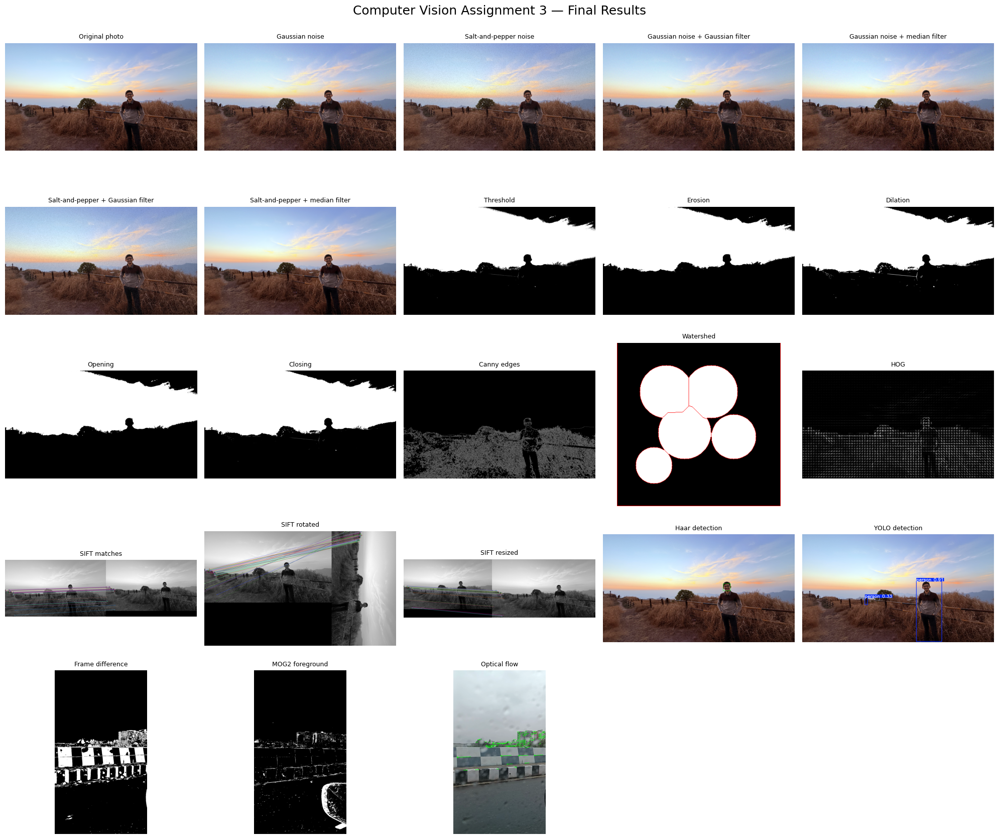


All image outputs are saved under: results/
Combined results overview: results/final_results_overview.png


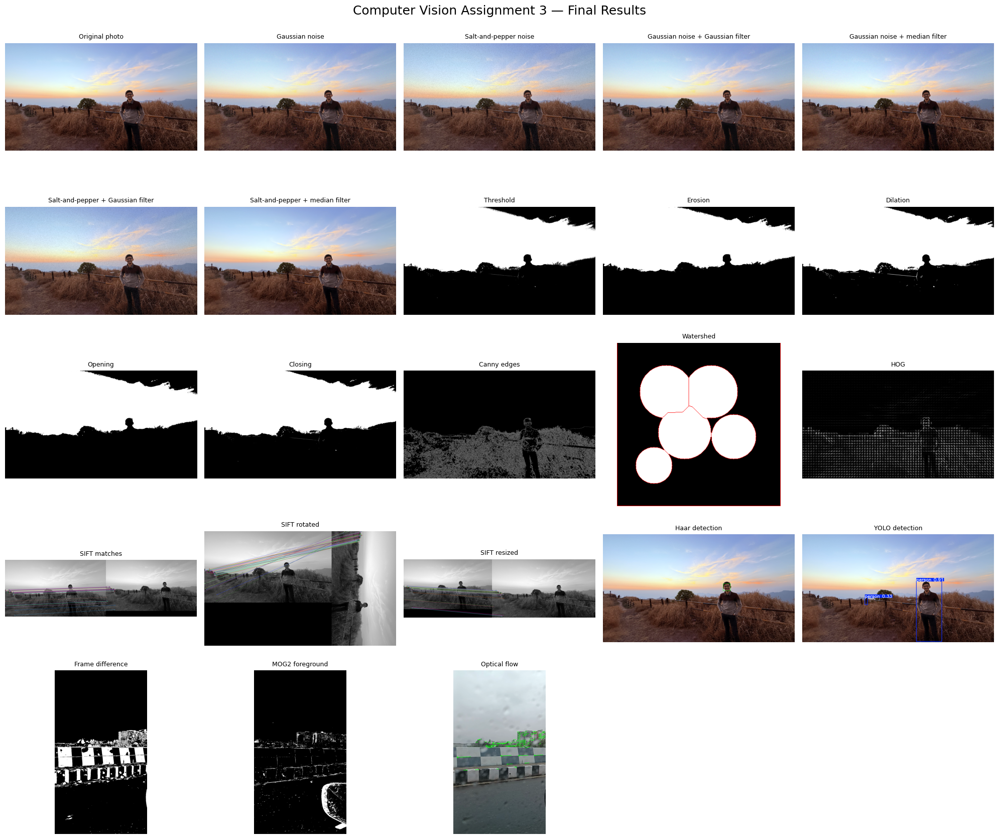

In [9]:
final_summary = pd.DataFrame([
    {"Task": "Image restoration", "Result": f"{len(restoration_metrics)} filter/noise combinations scored by PSNR and SSIM", "Artifacts": "Noisy and restored image comparisons"},
    {"Task": "Segmentation", "Result": "Thresholding, four morphology operations, Canny, watershed", "Artifacts": "Binary/morphology masks, edges, watershed boundaries"},
    {"Task": "Features and matching", "Result": f"{feature_results['SIFT keypoints in photo A']} and {feature_results['SIFT keypoints in photo B']} keypoints; {feature_results['Good matches']} initial good matches", "Artifacts": "HOG, SIFT, rotated and resized match visualizations"},
    {"Task": "Object detection", "Result": f"{detection_results['Haar faces']} Haar face(s); {detection_results['YOLO objects']} YOLO object(s)", "Artifacts": "Annotated Haar and YOLO outputs"},
    {"Task": "Motion estimation", "Result": "Frame differencing, MOG2, and Lucas–Kanade run on the supplied 54-frame video", "Artifacts": "Foreground masks and motion vectors"},
])
display(final_summary)

# Build one final contact sheet so every stage can be reviewed together.
overview_files = [
    ("Original photo", "../data/original_photo.png"),
    ("Gaussian noise", "noise_gaussian.png"),
    ("Salt-and-pepper noise", "noise_salt_pepper.png"),
    ("Gaussian noise + Gaussian filter", "restored_gaussian_noise_gaussian_filter.png"),
    ("Gaussian noise + median filter", "restored_gaussian_noise_median_filter.png"),
    ("Salt-and-pepper + Gaussian filter", "restored_salt_pepper_gaussian_filter.png"),
    ("Salt-and-pepper + median filter", "restored_salt_pepper_median_filter.png"),
    ("Threshold", "binary_threshold.png"),
    ("Erosion", "morph_erosion.png"),
    ("Dilation", "morph_dilation.png"),
    ("Opening", "morph_opening.png"),
    ("Closing", "morph_closing.png"),
    ("Canny edges", "edge_canny.png"),
    ("Watershed", "watershed_segmentation.png"),
    ("HOG", "hog_visualization.png"),
    ("SIFT matches", "sift_matches.png"),
    ("SIFT rotated", "sift_matches_rotated.png"),
    ("SIFT resized", "sift_matches_resized.png"),
    ("Haar detection", "haar_face_detection.png"),
    ("YOLO detection", "yolo_detection.png"),
    ("Frame difference", "frame_difference.png"),
    ("MOG2 foreground", "background_subtraction.png"),
    ("Optical flow", "optical_flow.png"),
]
fig, axes = plt.subplots(5, 5, figsize=(20, 17))
for ax, (caption, relative_path) in zip(axes.flat, overview_files):
    path = (RESULTS_DIR / relative_path).resolve()
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Missing final artifact: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(caption, fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(overview_files):]:
    ax.axis("off")
fig.suptitle("Computer Vision Assignment 3 — Final Results", fontsize=18)
plt.tight_layout()
overview_path = RESULTS_DIR / "final_results_overview.png"
fig.savefig(overview_path, dpi=120, bbox_inches="tight")
display(fig)
print(f"\nAll image outputs are saved under: {RESULTS_DIR.relative_to(ROOT)}/")
print(f"Combined results overview: {overview_path.relative_to(ROOT)}")

### Conclusion

The pipeline demonstrates the required image restoration, segmentation, feature extraction, object detection, and motion-estimation methods on the supplied photograph and available video. The PSNR/SSIM table enables a direct denoising comparison; the visual results show how segmentation and descriptors behave on the scene and the annotated detection/motion outputs make the recognition and temporal methods inspectable.
